In [1]:
import pandas as pd, numpy as np, os
from pathlib import Path

DATA = Path("/kaggle/input/competitions/h-and-m-personalized-fashion-recommendations")
OUT = Path("/kaggle/working"); OUT.mkdir(exist_ok=True)

print(os.listdir(DATA))
articles = pd.read_csv(DATA/"articles.csv", dtype={"article_id": str})
customers = pd.read_csv(DATA/"customers.csv")
print(articles.shape, customers.shape)
articles.head()

['sample_submission.csv', 'articles.csv', 'transactions_train.csv', 'images', 'customers.csv']
(105542, 25) (1371980, 7)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [2]:
tx = pd.read_csv(
    DATA/"transactions_train.csv",
    dtype={"article_id": str, "sales_channel_id": "int8", "price": "float32"},
    parse_dates=["t_dat"],
)
# customer_id es un hash largo; lo convertimos a un entero para ahorrar RAM
tx["customer_id"] = tx["customer_id"].str[-16:].apply(lambda x: int(x, 16)).astype("uint64")
print(tx.shape, tx.t_dat.min(), tx.t_dat.max())
print(tx.memory_usage(deep=True).sum() / 1e9, "GB")

(31788324, 5) 2018-09-20 00:00:00 2020-09-22 00:00:00
2.543066052 GB


In [3]:
def img_path(aid):
    return DATA/"images"/aid[:3]/f"{aid}.jpg"

articles["has_image"] = articles.article_id.map(lambda a: img_path(a).exists())
print("Sin imagen:", (~articles.has_image).sum())
print(articles.isna().sum()[articles.isna().sum() > 0])
articles.product_group_name.value_counts().head(15)

Sin imagen: 442
detail_desc    416
dtype: int64


product_group_name
Garment Upper body     42741
Garment Lower body     19812
Garment Full body      13292
Accessories            11158
Underwear               5490
Shoes                   5283
Swimwear                3127
Socks & Tights          2442
Nightwear               1899
Unknown                  121
Underwear/nightwear       54
Cosmetic                  49
Bags                      25
Items                     17
Furniture                 13
Name: count, dtype: int64

In [4]:
cols = ["prod_name", "product_type_name", "colour_group_name",
        "graphical_appearance_name", "section_name", "detail_desc"]
articles["text"] = articles[cols].fillna("").agg(". ".join, axis=1)
articles.text.iloc[0]

'Strap top. Vest top. Black. Solid. Womens Everyday Basics. Jersey top with narrow shoulder straps.'

In [5]:
VAL_START = tx.t_dat.max() - pd.Timedelta(days=6)   # última semana = validación
train = tx[tx.t_dat < VAL_START]
val = tx[tx.t_dat >= VAL_START]

# Subconjunto para iterar rápido: últimas 12 semanas de train
train_small = train[train.t_dat >= VAL_START - pd.Timedelta(weeks=12)]
print(len(train), len(train_small), len(val))

articles.to_parquet(OUT/"articles.parquet")
train.to_parquet(OUT/"train.parquet")
train_small.to_parquet(OUT/"train_small.parquet")
val.to_parquet(OUT/"val.parquet")

31548013 3664080 240311


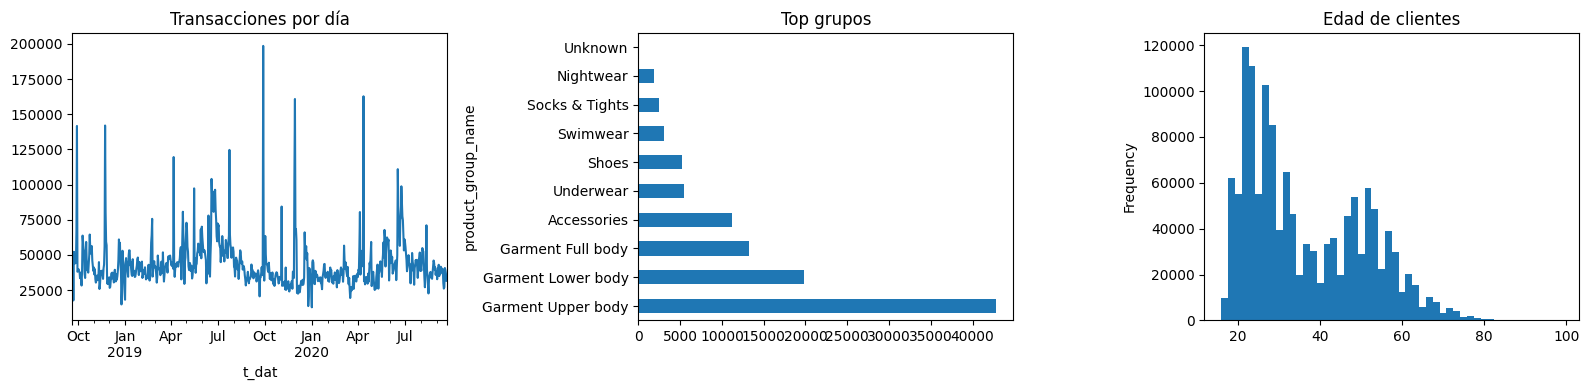

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
tx.groupby("t_dat").size().plot(ax=ax[0], title="Transacciones por día")
articles.product_group_name.value_counts().head(10).plot.barh(ax=ax[1], title="Top grupos")
customers.age.plot.hist(bins=50, ax=ax[2], title="Edad de clientes")
plt.tight_layout()